
Training with Learning Rate: 0.1
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Training with Learning Rate: 0.01
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Training with Learning Rate: 0.001
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan

Training with Learning Rate: 0.0001
Epoch 500, Loss 11.6281
Epoch 1000, Loss 9.2935
Epoch 1500, Loss 7.6317
Epoch 2000, Loss 6.4485
Epoch 2500, Loss 5.6058
Epoch 3000, Loss 5.0053
Epoch 3500, Loss 4.5770
Epoch 4000, Loss 4.2712
Epoch 4500, Loss 4.0526
Epoch 5000, Los

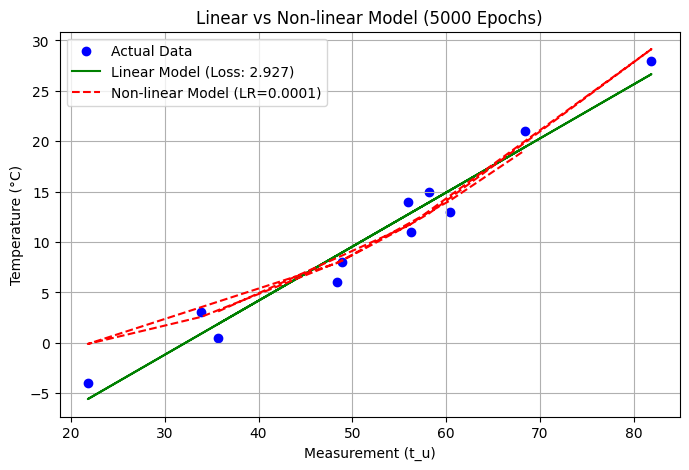


Final Non-linear Loss: 3.8957
Final Linear Loss: 2.9276


In [16]:
import torch
import matplotlib.pyplot as plt

t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])
t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])

t_un = 0.1 * t_u

def model(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

def training_loop(n_epochs, learning_rate, params, t_u, t_c, print_interval=500):
    for epoch in range(1, n_epochs + 1):
        if params.grad is not None:
            params.grad.zero_()

        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)
        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        if epoch % print_interval == 0:
            print(f'Epoch {epoch}, Loss {loss.item():.4f}')

    return params

learning_rates = [0.1, 0.01, 0.001, 0.0001]

for lr in learning_rates:
    print(f"\nTraining with Learning Rate: {lr}")

    params = torch.tensor([0.0, 1.0, 0.0], requires_grad=True)

    trained_params = training_loop(n_epochs=5000, learning_rate=lr, params=params, t_u=t_un, t_c=t_c)

print(f"\nTraining best non-linear model (LR = 0.0001)")
best_params = torch.tensor([0.0, 1.0, 0.0], requires_grad=True)
best_params = training_loop(n_epochs=5000, learning_rate=0.0001, params=best_params, t_u=t_un, t_c=t_c)

linear_w = 5.3671
linear_b = -17.3012
t_p_linear = linear_w * t_un + linear_b

t_p_nonlinear = model(t_un, *best_params)

plt.figure(figsize=(8, 5))

plt.scatter(t_u.numpy(), t_c.numpy(), label='Actual Data', color='blue')

plt.plot(t_u.numpy(), t_p_linear.detach().numpy(), label='Linear Model (Loss: 2.927)', color='green')

plt.plot(t_u.numpy(), t_p_nonlinear.detach().numpy(), label='Non-linear Model (LR=0.0001)', color='red', linestyle='--')

plt.xlabel('Measurement (t_u)')
plt.ylabel('Temperature (°C)')
plt.title('Linear vs Non-linear Model (5000 Epochs)')
plt.legend()
plt.grid(True)
plt.show()

final_nonlinear_loss = loss_fn(t_p_nonlinear, t_c).item()
print(f"\nFinal Non-linear Loss: {final_nonlinear_loss:.4f}")
print(f"Final Linear Loss: 2.9276")


Training with Learning Rate: 0.1
Epoch  500 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 1000 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 1500 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 2000 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 2500 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 3000 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 3500 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 4000 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 4500 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00
Epoch 5000 | Train Loss: 741122375680.00 | Val Loss: 870648315904.00

Training with Learning Rate: 0.01
Epoch  500 | Train Loss: 741753356288.00 | Val Loss: 866575122432.00
Epoch 1000 | Train Loss: 741122768896.00 | Val Loss: 870593265664.00
Epoch 1500 | Train Loss: 741122375680.00 | Val Loss: 870643531776.00
Epoch 2000 | Train Loss: 741122375

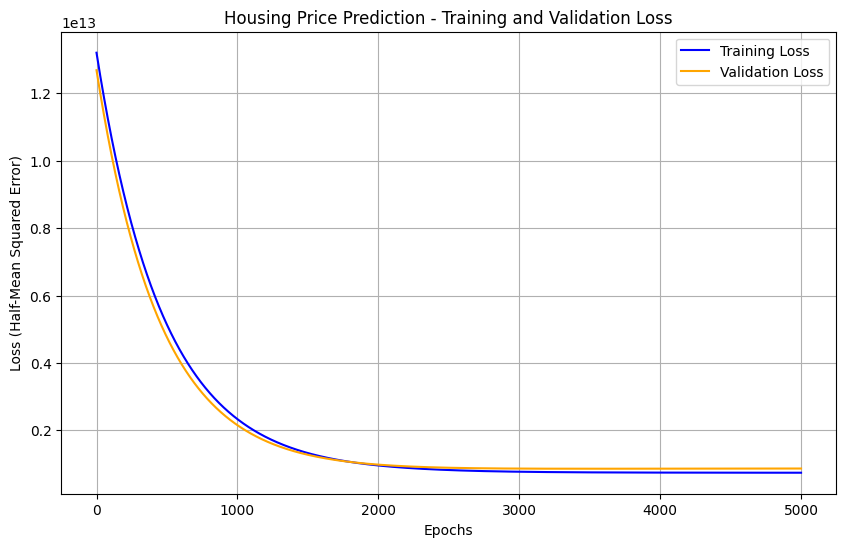

In [17]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("/content/Housing.csv")

X = data[["area", "bedrooms", "bathrooms", "stories", "parking"]].values
y = data["price"].values
m = len(y)

np.random.seed(7)
indices = np.random.permutation(m)
split_index = int(0.8 * m)

train_indices = indices[:split_index]
validation_indices = indices[split_index:]

X_train = X[train_indices]
y_train = y[train_indices]
X_val = X[validation_indices]
y_val = y[validation_indices]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

def model(X, params):
    return params[0] + X @ params[1:]

def loss_fn(t_p, t_c):
    return torch.mean((t_p - t_c)**2) / 2

def training_loop(n_epochs, learning_rate, params, X_train, y_train, X_val, y_val):
    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):
        if params.grad is not None:
            params.grad.zero_()

        t_p = model(X_train, params)
        loss = loss_fn(t_p, y_train)

        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        t_p_val = model(X_val, params)
        val_loss = loss_fn(t_p_val, y_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        if epoch % 500 == 0:
            print(f'Epoch {epoch:4d} | Train Loss: {loss.item():.2f} | Val Loss: {val_loss.item():.2f}')

    return params, train_losses, val_losses

learning_rates = [0.1, 0.01, 0.001, 0.0001]

best_loss = float('inf')
best_params = None
best_history = None

for lr in learning_rates:
    print(f"\nTraining with Learning Rate: {lr}")

    params = torch.zeros(6, dtype=torch.float32, requires_grad=True)

    trained_params, train_hist, val_hist = training_loop(
        n_epochs=5000,
        learning_rate=lr,
        params=params,
        X_train=X_train_t, y_train=y_train_t,
        X_val=X_val_t, y_val=y_val_t
    )

    final_val_loss = val_hist[-1]
    if final_val_loss < best_loss:
        best_loss = final_val_loss
        best_params = trained_params
        best_history = (train_hist, val_hist)

print("\nBest Model Parameters (Thetas)")
print(f"t0 (Bias): {best_params[0].item():.4f}")
for i in range(5):
    print(f"t{i+1}: {best_params[i+1].item():.4f}")

plt.figure(figsize=(10, 6))
plt.plot(best_history[0], label="Training Loss", color="blue")
plt.plot(best_history[1], label="Validation Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss (Half-Mean Squared Error)")
plt.title("Housing Price Prediction - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("/content/Housing.csv")

binary_vars = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

for var in binary_vars:
    if var in data.columns:
        data[var] = data[var].map({"yes": 1, "no": 0})

feature_cols = [
    "area", "bedrooms", "bathrooms", "stories",
    "mainroad", "guestroom", "basement", "hotwaterheating",
    "airconditioning", "parking", "prefarea"
]

X = data[feature_cols].values
y = data["price"].values
m = len(y)

np.random.seed(7)
indices = np.random.permutation(m)
split_index = int(0.8 * m)

train_indices = indices[:split_index]
validation_indices = indices[split_index:]

X_train = X[train_indices]
y_train = y[train_indices]
X_val = X[validation_indices]
y_val = y[validation_indices]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

def model(X, params):
    return params[0] + X @ params[1:]

def loss_fn(t_p, t_c):
    return torch.mean((t_p - t_c)**2) / 2

def training_loop(n_epochs, learning_rate, params, X_train, y_train, X_val, y_val):
    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):
        if params.grad is not None:
            params.grad.zero_()

        t_p = model(X_train, params)
        loss = loss_fn(t_p, y_train)

        loss.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        t_p_val = model(X_val, params)
        val_loss = loss_fn(t_p_val, y_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        if epoch % 500 == 0:
            print(f'Epoch {epoch:4d} | Train Loss: {loss.item():.2f} | Val Loss: {val_loss.item():.2f}')

    return params, train_losses, val_losses

learning_rates = [0.1, 0.01, 0.001, 0.0001]

best_loss = float('inf')
best_params = None
best_history = None

for lr in learning_rates:
    print(f"\nTraining with Learning Rate: {lr}")

    params = torch.zeros(12, dtype=torch.float32, requires_grad=True)

    trained_params, train_hist, val_hist = training_loop(
        n_epochs=5000,
        learning_rate=lr,
        params=params,
        X_train=X_train_t, y_train=y_train_t,
        X_val=X_val_t, y_val=y_val_t
    )

    final_val_loss = val_hist[-1]
    if final_val_loss < best_loss:
        best_loss = final_val_loss
        best_params = trained_params
        best_history = (train_hist, val_hist)

print("\nBest Model Parameters (Thetas)")
print(f"t0 (Bias): {best_params[0].item():.4f}")
for i in range(11):
    print(f"t{i+1} ({feature_cols[i]}): {best_params[i+1].item():.4f}")

plt.figure(figsize=(10, 6))
plt.plot(best_history[0], label="Training Loss", color="blue")
plt.plot(best_history[1], label="Validation Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss (Half-Mean Squared Error)")
plt.title("Housing Price Prediction (All Features) - Loss")
plt.legend()
plt.grid(True)
plt.show()


Training with Learning Rate: 0.1
Epoch  500 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 1000 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 1500 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 2000 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 2500 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 3000 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 3500 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 4000 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 4500 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00
Epoch 5000 | Train Loss: 572290826240.00 | Val Loss: 571311718400.00

Training with Learning Rate: 0.01
Epoch  500 | Train Loss: 572980854784.00 | Val Loss: 570369441792.00
Epoch 1000 | Train Loss: 572293513216.00 | Val Loss: 571242971136.00
Epoch 1500 | Train Loss: 572290891776.00 | Val Loss: 571300249600.00
Epoch 2000 | Train Loss: 572290891